# 04 — Comarca Context, Territorial Profiles and Fieldwork Candidates

## 1. Objective and research questions

**Objective.** Notebook 03 measured the senior population by comarca. This notebook adds the **context** that matters for an activities marketplace and uses it to (a) describe transparent **territorial profiles** and (b) propose **candidate comarques for fieldwork** (supply inventory and survey). The aim is to choose places for empirical research, not to rank markets: no "opportunity score" is computed (decision D-007).

**Research questions**

1. **Living alone.** How many people aged 75+ live alone in each comarca? Living alone is a commonly cited risk factor for loneliness and a possible driver of interest in social activities (a hypothesis, not tested here).
2. **Settlement and density.** How urban or rural is each comarca, and how dense?
3. **Socioeconomic level and education.** How do comarques compare on Idescat's territorial socioeconomic index (IST) and on education level?
4. **Digital use.** What is known about internet use among older people in Catalonia, a condition for using a digital marketplace?
5. **Profiles.** Can comarques be grouped into a few transparent profiles using simple, documented rules (no clustering)? How sensitive is the grouping to the rule thresholds?
6. **Fieldwork.** Which comarques could represent each profile in the supply inventory and the survey, and what does their municipal structure look like?

**Inputs from notebook 03.** The tables in `data/processed/comarca_*.csv` (versioned). Notebook 03 must have been run first.

## 2. Data sources

New datasets, downloaded with `python scripts/download_idescat.py` (URLs, times and SHA-256 in `data/raw/idescat_api/MANIFEST.csv`; documented in `docs/data_sources.md`):

| ID | Dataset | Reference | Geography | Notes |
|---|---|---|---|---|
| DS-12 | Census household indicators (`censph` 17317/20806), incl. % of people 75+ living alone | 2021 | Comarca (2021 boundaries) and municipality | Only year available. Suppressed (`..`) for 486 small municipalities |
| DS-13 | Census education indicators, population 15+ (`censph` 16719/20207) | 2021–2024 | Comarca | Not broken down by age |
| DS-14 | Degree of urbanisation indicators (`degurba` 17107/20579): population, area, density, % living in urban centres / urban clusters / rural cells | 2025 | Municipality and comarca | Eurostat DEGURBA method on a 1 km² grid |
| DS-15 | Territorial socioeconomic index, IST (`ist` 14034/14994), Catalonia = 100, and its components (`ist` 14074/15022) | 2024 (provisional) | Comarca | Combines employment, occupation skill, education, origin and income |
| DS-16 | ICT household survey 2025 (`ticll25`), main ICT use indicators by age, persons 16–74 | 2025 | Catalonia | Sample survey (INE, expanded by Idescat). **No data for 75+.** |

Reused: notebook 03 outputs, census by municipality 2025 (DS-08), census by comarca 2021 (DS-07), code list (DS-11).

Attribution: *Idescat. Cens de població i habitatges; Estadística del grau d'urbanització; Índex socioeconòmic territorial; Enquesta sobre equipament i ús de TIC a les llars (Idescat, from INE).*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from tfg.idescat import read_jsonstat, read_idescat_html_tables, age_group_lower_bound
from tfg.territory import municipality_to_comarca_2025
from tfg.paths import IDESCAT_API_RAW, DATA_PROCESSED, REPORTS_FIGURES

REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
CATALONIA = "Catalunya"

## 3. Data preparation

### 3.1 Notebook 03 outputs

In [2]:
senior = pd.read_csv(DATA_PROCESSED / "comarca_senior_context_table.csv").set_index("comarca")
indicators_2025 = pd.read_csv(DATA_PROCESSED / "comarca_senior_indicators_2025.csv").set_index("comarca")
senior = senior.join(indicators_2025[["pop_total", "pop_65_plus", "pop_75_plus", "share_65_plus", "ageing_index"]])
assert len(senior) == 43 and senior.notna().all().all()
CATALONIA_SHARE_60 = 100 * senior["pop_60_plus"].sum() / senior["pop_total"].sum()
print(f"Comarques: {len(senior)} | Catalonia share 60+: {CATALONIA_SHARE_60:.2f} %")

Comarques: 43 | Catalonia share 60+: 25.93 %


### 3.2 Degree of urbanisation (DS-14) — rebuilt from municipalities and checked

Areas and populations are additive, so the municipal table is aggregated to the 1 Jan 2025 comarques and compared with Idescat's comarca table. Percentages are re-weighted by population.

In [3]:
mun_to_comarca = municipality_to_comarca_2025()
degurba_mun = read_jsonstat(IDESCAT_API_RAW / "degurba_17107_20579_mun_2025.json")
degurba_mun = degurba_mun.loc[degurba_mun["MUN"] != "TOTAL"].pivot(index="MUN", columns="CONCEPT", values="value")
assert degurba_mun.notna().all().all() and len(degurba_mun) == 947
degurba_mun = degurba_mun.merge(mun_to_comarca[["mun_code", "mun_name", "comarca_name"]],
                                left_index=True, right_on="mun_code", validate="one_to_one")
for col in ["PERC_CIT", "PERC_TOWM_SEM_DENS", "PERC_RUR_AREA"]:
    degurba_mun[col + "_people"] = degurba_mun[col] / 100 * degurba_mun["POP"]
urban = degurba_mun.groupby("comarca_name")[["POP", "SURFACE_KM2", "PERC_CIT_people",
                                              "PERC_TOWM_SEM_DENS_people", "PERC_RUR_AREA_people"]].sum()
urban["density_per_km2"] = urban["POP"] / urban["SURFACE_KM2"]
urban["pct_urban_centres"] = 100 * urban["PERC_CIT_people"] / urban["POP"]
urban["pct_urban_clusters"] = 100 * urban["PERC_TOWM_SEM_DENS_people"] / urban["POP"]
urban["pct_rural_cells"] = 100 * urban["PERC_RUR_AREA_people"] / urban["POP"]

degurba_com = read_jsonstat(IDESCAT_API_RAW / "degurba_17107_20579_com.json")
degurba_com = degurba_com.loc[degurba_com["COM"] != "TOTAL"].pivot(index="COM_label", columns="CONCEPT", values="value")
assert (urban["POP"] - degurba_com["POP"]).abs().max() == 0
assert (urban["SURFACE_KM2"] - degurba_com["SURFACE_KM2"]).abs().max() < 1e-6
assert (urban["pct_rural_cells"] - degurba_com["PERC_RUR_AREA"]).abs().max() < 0.1
assert (urban["POP"] == senior["pop_total"].reindex(urban.index)).all(), "degurba population = census 2025"
urban = urban[["SURFACE_KM2", "density_per_km2", "pct_urban_centres", "pct_urban_clusters", "pct_rural_cells"]].rename(
    columns={"SURFACE_KM2": "area_km2"})
print("Rebuilt comarques match Idescat's comarca table and the 2025 census population.")

Rebuilt comarques match Idescat's comarca table and the 2025 census population.


### 3.3 People aged 75+ living alone, 2021 (DS-12)

Only the 2021 census provides this. Two routes were tested:

- *Rebuilding from municipalities* was rejected: Idescat suppresses the value for 486 small municipalities, which biased rural comarques by up to 2.6 percentage points.
- The **published comarca values** are used instead. They use the **2021 boundaries**, which differ from the 1 Jan 2025 division only for Osona, Segarra and Solsonès (flagged). Lluçanès did not exist in 2021, so it has no value.

An *estimated number* of people aged 75+ living alone = published share × census 2021 population aged 75+ of the same comarca (same boundaries). It is labelled as an estimate.

In [4]:
households = read_jsonstat(IDESCAT_API_RAW / "censph_17317_20806_com.json")
households = households.pivot(index="COM_label", columns="CONCEPT", values="value")
census_com = read_jsonstat(IDESCAT_API_RAW / "censph_539_5976_com.json")
c21 = census_com.loc[(census_com["YEAR"] == "2021") & (census_com["SEX"] == "TOTAL")].copy()
c21["age_lower"] = c21["AGE"].map(age_group_lower_bound)
pop75_2021 = c21.loc[c21["age_lower"] >= 75].groupby("COM_label")["value"].sum()

living_alone = pd.DataFrame({
    "pct_75plus_living_alone_2021": households["O75Y_ALO_PEOPLE_SH"],
    "pct_one_person_households_65plus_2021": households["O65Y_PEOPLE_HOU_SH"],
})
living_alone["est_75plus_living_alone_2021"] = (living_alone["pct_75plus_living_alone_2021"] / 100 * pop75_2021).round(-1)
catalonia_alone = living_alone.loc[CATALONIA]
living_alone = living_alone.drop(index=CATALONIA)
living_alone["boundary_flag"] = np.where(living_alone.index.isin(["Osona", "Segarra", "Solsonès"]), "2021 boundaries differ", "")
living_alone = living_alone.reindex(senior.index)
living_alone.loc["Lluçanès", "boundary_flag"] = "comarca did not exist in 2021"
assert living_alone.drop(index="Lluçanès")["pct_75plus_living_alone_2021"].notna().all()
print(f"Catalonia 2021: {catalonia_alone.pct_75plus_living_alone_2021:.1f} % of people aged 75+ live alone "
      f"(~{catalonia_alone.est_75plus_living_alone_2021:,.0f} people)")

Catalonia 2021: 28.1 % of people aged 75+ live alone (~205,370 people)


### 3.4 Socioeconomic index (DS-15) and education (DS-13)

Both are published for the comarques in force in 2024 (42 + Aran, i.e. the 1 Jan 2025 division). The 2024 IST is provisional; its income component is not yet available for that year.

In [5]:
ist = read_jsonstat(IDESCAT_API_RAW / "ist_14034_14994_com.json")
ist_2024 = ist.loc[ist["YEAR"] == "2024"].set_index("COM_label")["value"].rename("ist_index_2024")
assert ist.loc[ist["YEAR"] == "2024", "status"].eq("p").all()

education = read_jsonstat(IDESCAT_API_RAW / "censph_16719_20207_com.json")
education = education.loc[(education["YEAR"] == "2024") & (education["SEX"] == "TOTAL")].pivot(
    index="COM_label", columns="CONCEPT", values="value")
education = education.rename(columns={"PP_PE_Y15O": "pct_15plus_primary_or_less_2024",
                                      "P_EH_Y15O": "pct_15plus_higher_education_2024"})[
    ["pct_15plus_primary_or_less_2024", "pct_15plus_higher_education_2024"]]

context = (senior
           .join(urban)
           .join(living_alone)
           .join(ist_2024)
           .join(education))
assert len(context) == 43
assert context.drop(columns=["pct_75plus_living_alone_2021", "pct_one_person_households_65plus_2021",
                             "est_75plus_living_alone_2021"]).notna().all().all()
print("Context table:", context.shape)
print("Catalonia: IST 2024 =", ist_2024[CATALONIA], "| higher education 15+ =",
      education.loc[CATALONIA, "pct_15plus_higher_education_2024"], "%")

Context table: (43, 27)
Catalonia: IST 2024 = 100.0 | higher education 15+ = 36.7 %


### 3.5 Digital use by age, Catalonia 2025 (DS-16)

In [6]:
ict_tables = read_idescat_html_tables(IDESCAT_API_RAW / "ticll25_1_2_1_ict_use_by_person.html")
ict_caption, ict = ict_tables[0]
print(ict_caption)
ict_age = ict.loc[ict["group"] == "Edat"].set_index("category").drop(columns="group")
ict_age.columns = ["persons", "mobile_phone_use_pct", "internet_last_3_months_pct",
                   "regular_internet_use_pct", "online_purchase_last_3_months_pct"]
assert len(ict_age) == 6 and ict_age.notna().all().all()
display(ict_age)

Persones de 16 a 74 anys. Catalunya. 2025 Per característiques demogràfiques i principals variables d'ús de les TIC


,persons,mobile_phone_use_pct,internet_last_3_months_pct,regular_internet_use_pct,online_purchase_last_3_months_pct
category,,,,,
De 16 a 24 anys,833006.0,100.0,100.0,99.1,68.8
De 25 a 34 anys,987757.0,100.0,100.0,100.0,75.1
De 35 a 44 anys,1096323.0,99.3,98.8,97.9,75.5
De 45 a 54 anys,1320820.0,99.6,98.3,97.8,68.9
De 55 a 64 anys,1078246.0,98.8,96.1,94.4,57.7
De 65 a 74 anys,801665.0,97.4,92.7,90.2,36.1


## 4. Exploratory analysis

,density_per_km2,pct_rural_cells,pct_75plus_living_alone_2021,ist_index_2024,pct_15plus_higher_education_2024
count,43.0,43.0,42.0,43.0,43.0
mean,626.5,40.9,27.1,95.4,32.0
std,2506.1,30.7,2.5,6.4,4.7
min,5.3,0.0,18.4,83.2,22.0
25%,26.1,17.4,25.9,90.0,29.0
50%,87.6,38.5,27.3,95.8,31.5
75%,201.1,59.8,28.4,100.6,35.3
max,16454.8,100.0,33.4,106.9,44.3


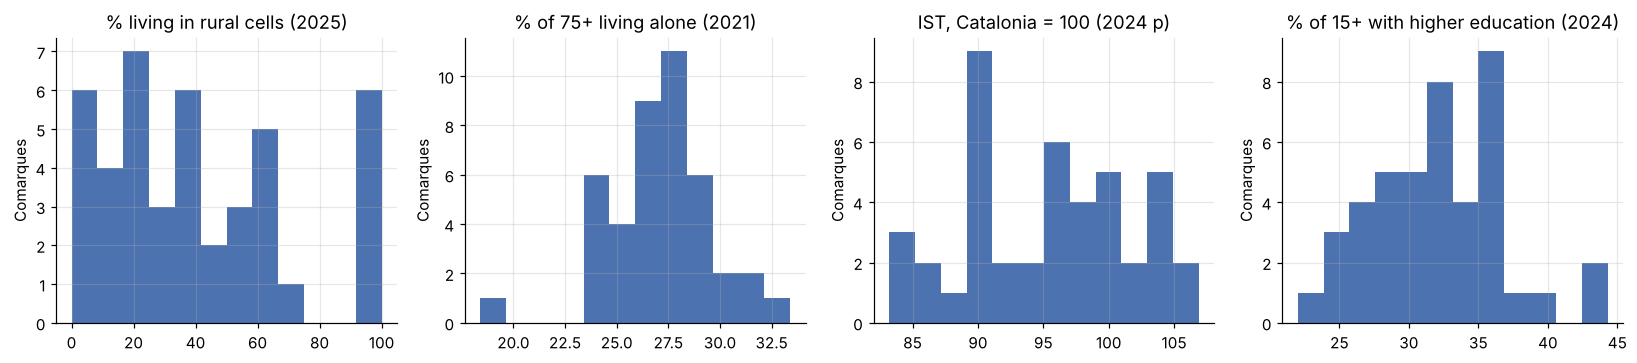

In [7]:
show = ["density_per_km2", "pct_rural_cells", "pct_75plus_living_alone_2021", "ist_index_2024",
        "pct_15plus_higher_education_2024"]
display(context[show].describe().round(1))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col, label in zip(axes, ["pct_rural_cells", "pct_75plus_living_alone_2021", "ist_index_2024",
                                 "pct_15plus_higher_education_2024"],
                          ["% living in rural cells (2025)", "% of 75+ living alone (2021)",
                           "IST, Catalonia = 100 (2024 p)", "% of 15+ with higher education (2024)"]):
    ax.hist(context[col].dropna(), bins=12, color="#4C72B0")
    ax.set(title=label, ylabel="Comarques")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "04_context_distributions.png", bbox_inches="tight"); plt.show()

Density varies by three orders of magnitude (from a few people per km² in the Pyrenees to over 16,000 in Barcelonès), and about half the comarques have most of their population in rural grid cells. The socioeconomic index ranges more narrowly, from 83 to 107 (Catalonia = 100).

## 5. Analytical methods

- **Associations:** Spearman rank correlations between the senior indicators (notebook 03) and the context variables, n = 43. They are descriptive only.
- **Territorial profiles:** deterministic rules, applied in order, using four documented variables. No clustering is used: with 43 units and mixed-scale variables, simple rules are easier to explain, reproduce and challenge.

| Variable | Definition | Threshold |
|---|---|---|
| Size | Residents 60+ (2025), split into thirds | small < 8,797 ≤ medium < 40,463 ≤ large |
| Seasonal | ETCA population as % of residents (2024) | ≥ 110 % |
| Rural | % of residents living in rural grid cells (2025) | ≥ 50 % |
| Aged | Share 60+ above Catalonia (25.9 %) | > Catalonia |

Rules, first match wins: **P2** seasonal and medium/large → **P3** seasonal and small → **P1** large (non-seasonal) → **P4** aged and rural → **P5** intermediate (the rest).

- **Sensitivity:** each threshold is moved (rural 40/60 %, seasonal 105/115 %, share ±1 pp), and the comarques that change profile are listed.
- **Fieldwork candidates:** for each profile, the member comarques are compared side by side. Candidates are suggested with stated, qualitative reasons (representativeness within the profile, size of the senior population, continuity with the Costa Brava case). The final choice is the author's and tutor's.

## 6. Results

### 6.1 Context variables and the senior population

,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,density_per_km2,pct_rural_cells,pct_75plus_living_alone_2021,ist_index_2024,pct_15plus_higher_education_2024,rfdb_per_capita_eur_2023,etca_pct_of_resident_2024
pop_60_plus,1.00,-0.58,0.34,0.91,-0.90,-0.08,-0.03,0.04,0.39,-0.20
share_60_plus,-0.58,1.00,-0.70,-0.67,0.66,0.18,-0.10,-0.16,-0.34,0.18
pct_change_60_plus_2021_2025,0.34,-0.70,1.00,0.52,-0.47,-0.18,0.23,0.21,0.22,0.07


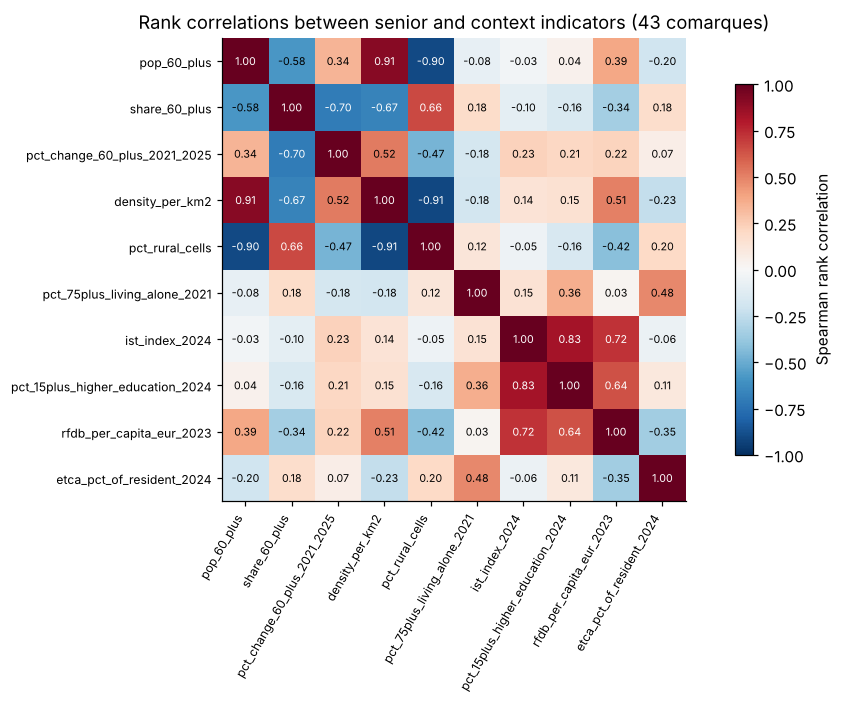

In [8]:
assoc_cols = ["pop_60_plus", "share_60_plus", "pct_change_60_plus_2021_2025", "density_per_km2", "pct_rural_cells",
              "pct_75plus_living_alone_2021", "ist_index_2024", "pct_15plus_higher_education_2024",
              "rfdb_per_capita_eur_2023", "etca_pct_of_resident_2024"]
spearman = context[assoc_cols].corr(method="spearman")
display(spearman.loc[["pop_60_plus", "share_60_plus", "pct_change_60_plus_2021_2025"]].round(2))

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(spearman.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(assoc_cols)), assoc_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(assoc_cols)), assoc_cols, fontsize=8)
for i in range(len(assoc_cols)):
    for j in range(len(assoc_cols)):
        ax.text(j, i, f"{spearman.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(spearman.values[i, j]) > 0.6 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman rank correlation")
ax.set_title("Rank correlations between senior and context indicators (43 comarques)")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "04_correlations.png", bbox_inches="tight"); plt.show()

### 6.2 People aged 75+ living alone (2021)

Catalonia: 28.1 % of 75+ live alone; estimated 205,370 people (2021)
Highest and lowest shares:


,pop_75_plus,pct_75plus_living_alone_2021,est_75plus_living_alone_2021,boundary_flag
comarca,,,,
Pallars Jussà,1812,33.4,600.0,
Alta Ribagorça,401,31.6,130.0,
Barcelonès,263441,31.1,77560.0,
Pallars Sobirà,716,30.0,210.0,
Ripollès,3383,29.7,980.0,
Baix Camp,18591,29.3,4740.0,
Baix Ebre,9612,24.6,2230.0,
Pla de l'Estany,3133,24.4,710.0,
Moianès,1530,23.9,340.0,


Three largest comarques hold 56 % of the estimated 75+ living alone.


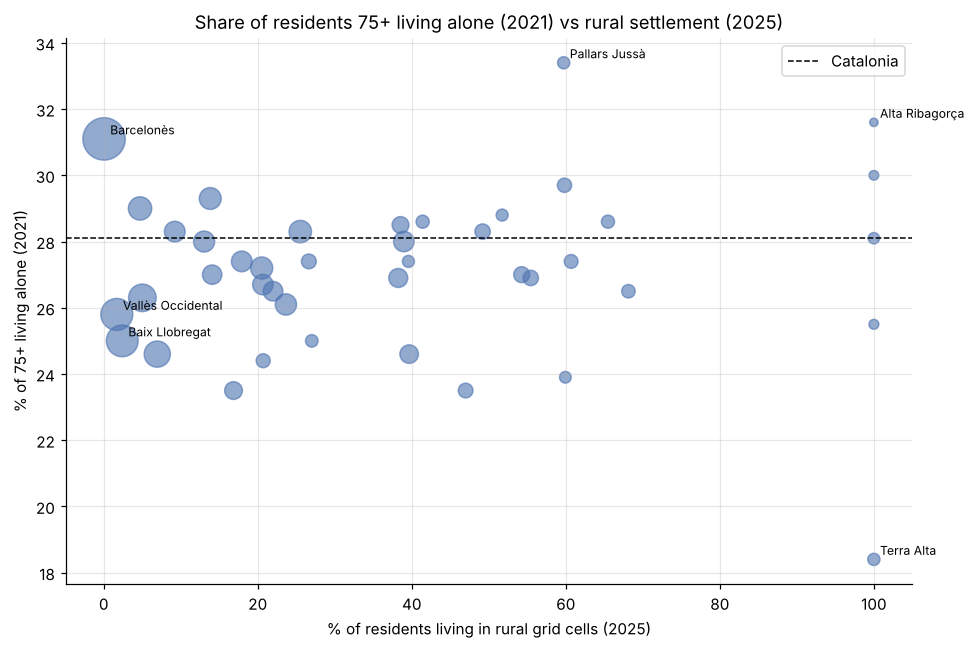

In [9]:
alone = context[["pop_75_plus", "pct_75plus_living_alone_2021", "est_75plus_living_alone_2021", "boundary_flag"]]
print(f"Catalonia: {catalonia_alone.pct_75plus_living_alone_2021:.1f} % of 75+ live alone; "
      f"estimated {catalonia_alone.est_75plus_living_alone_2021:,.0f} people (2021)")
top_share = alone.dropna(subset=["pct_75plus_living_alone_2021"]).sort_values("pct_75plus_living_alone_2021", ascending=False)
print("Highest and lowest shares:")
display(pd.concat([top_share.head(6), top_share.tail(6)]).round(1))
est = alone["est_75plus_living_alone_2021"].dropna()
print(f"Three largest comarques hold {100 * est.nlargest(3).sum() / est.sum():.0f} % of the estimated 75+ living alone.")

fig, ax = plt.subplots(figsize=(9, 6))
d = context.dropna(subset=["pct_75plus_living_alone_2021"])
ax.scatter(d["pct_rural_cells"], d["pct_75plus_living_alone_2021"], s=np.sqrt(d["pop_75_plus"]) * 1.5,
           alpha=0.6, color="#4C72B0")
ax.axhline(catalonia_alone.pct_75plus_living_alone_2021, color="black", ls="--", lw=1, label="Catalonia")
for name, r in d.iterrows():
    if r["pct_75plus_living_alone_2021"] > 31 or r["pct_75plus_living_alone_2021"] < 22 or r["pop_75_plus"] > 60_000:
        ax.annotate(name, (r["pct_rural_cells"], r["pct_75plus_living_alone_2021"]), fontsize=8,
                    xytext=(4, 3), textcoords="offset points")
ax.set(title="Share of residents 75+ living alone (2021) vs rural settlement (2025)",
       xlabel="% of residents living in rural grid cells (2025)", ylabel="% of 75+ living alone (2021)")
ax.legend()
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "04_living_alone_vs_rural.png", bbox_inches="tight"); plt.show()

### 6.3 Digital use by age (Catalonia, 2025)

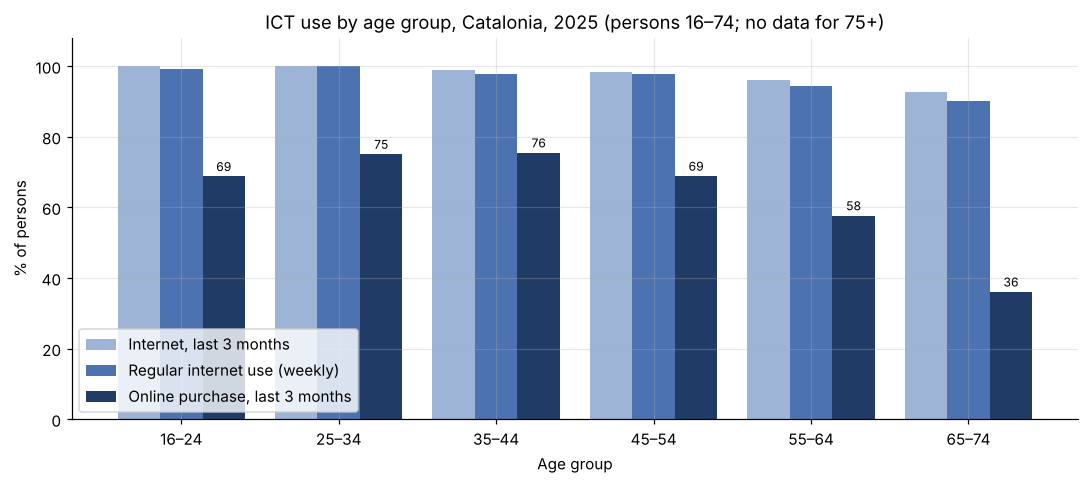

,persons,mobile_phone_use_pct,internet_last_3_months_pct,regular_internet_use_pct,online_purchase_last_3_months_pct
category,,,,,
De 16 a 24 anys,833006.0,100.0,100.0,99.1,68.8
De 25 a 34 anys,987757.0,100.0,100.0,100.0,75.1
De 35 a 44 anys,1096323.0,99.3,98.8,97.9,75.5
De 45 a 54 anys,1320820.0,99.6,98.3,97.8,68.9
De 55 a 64 anys,1078246.0,98.8,96.1,94.4,57.7
De 65 a 74 anys,801665.0,97.4,92.7,90.2,36.1


In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cols = {"internet_last_3_months_pct": "Internet, last 3 months",
        "regular_internet_use_pct": "Regular internet use (weekly)",
        "online_purchase_last_3_months_pct": "Online purchase, last 3 months"}
x = np.arange(len(ict_age))
for k, (col, label) in enumerate(cols.items()):
    ax.bar(x + (k - 1) * 0.27, ict_age[col], width=0.27, label=label, color=["#9DB4D6", "#4C72B0", "#1F3B66"][k])
for i, v in enumerate(ict_age["online_purchase_last_3_months_pct"]):
    ax.text(i + 0.27, v + 1.5, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x, [c.replace("De ", "").replace(" anys", "").replace(" a ", "–") for c in ict_age.index])
ax.set(title="ICT use by age group, Catalonia, 2025 (persons 16–74; no data for 75+)", ylabel="% of persons",
       xlabel="Age group", ylim=(0, 108))
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "04_ict_use_by_age.png", bbox_inches="tight"); plt.show()
display(ict_age.round(1))

### 6.4 Territorial profiles

In [11]:
SEASONAL_CUT, RURAL_CUT = 110, 50
context["size_third"] = pd.qcut(context["pop_60_plus"], 3, labels=["small", "medium", "large"])
print(context.groupby("size_third", observed=True)["pop_60_plus"].agg(["count", "min", "max"]))

PROFILE_NAMES = {
    "P1": "P1 Large, non-seasonal",
    "P2": "P2 Seasonal, medium/large",
    "P3": "P3 Seasonal, small",
    "P4": "P4 Aged and rural",
    "P5": "P5 Intermediate",
}

def assign_profile(r, rural_cut=RURAL_CUT, seasonal_cut=SEASONAL_CUT, share_cut=CATALONIA_SHARE_60):
    seasonal = r["etca_pct_of_resident_2024"] >= seasonal_cut
    rural = r["pct_rural_cells"] >= rural_cut
    if seasonal and r["size_third"] != "small":
        return "P2"
    if seasonal:
        return "P3"
    if r["size_third"] == "large":
        return "P1"
    if r["share_60_plus"] > share_cut and rural:
        return "P4"
    return "P5"

context["profile"] = context.apply(assign_profile, axis=1)
profile_summary = context.groupby("profile").agg(
    comarques=("pop_60_plus", "size"),
    residents_60_plus=("pop_60_plus", "sum"),
    median_share_60_plus=("share_60_plus", "median"),
    median_growth_60_plus_2021_2025=("pct_change_60_plus_2021_2025", "median"),
    median_projected_growth_2025_2040=("pct_change_60_plus_2025_2040_medium", "median"),
    median_rural_pct=("pct_rural_cells", "median"),
    median_75plus_alone_pct=("pct_75plus_living_alone_2021", "median"),
    median_ist=("ist_index_2024", "median"),
)
profile_summary["pct_of_catalonia_60_plus"] = 100 * profile_summary["residents_60_plus"] / context["pop_60_plus"].sum()
profile_summary.index = profile_summary.index.map(PROFILE_NAMES)
display(profile_summary.round(1))
for p, g in context.groupby("profile"):
    print(f"{PROFILE_NAMES[p]}: {', '.join(g.sort_values('pop_60_plus', ascending=False).index)}")

            count    min     max
size_third                      
small          15   1148    7555
medium         14   8797   39001
large          14  40463  631118


,comarques,residents_60_plus,median_share_60_plus,median_growth_60_plus_2021_2025,median_projected_growth_2025_2040,median_rural_pct,median_75plus_alone_pct,median_ist,pct_of_catalonia_60_plus
profile,,,,,,,,,
"P1 Large, non-seasonal",11,1611655,25.5,10.7,44.6,9.2,27.4,100.9,76.5
"P2 Seasonal, medium/large",6,237359,26.4,12.7,45.7,22.2,27.5,90.7,11.3
"P3 Seasonal, small",4,11147,27.1,10.7,47.9,100.0,29.4,102.0,0.5
P4 Aged and rural,10,63652,33.4,6.5,22.7,63.1,27.0,94.4,3.0
P5 Intermediate,12,182687,26.7,9.2,39.9,38.4,26.7,90.6,8.7


P1 Large, non-seasonal: Barcelonès, Vallès Occidental, Baix Llobregat, Maresme, Vallès Oriental, Segrià, Baix Camp, Bages, Gironès, Garraf, Osona
P2 Seasonal, medium/large: Tarragonès, Selva, Baix Empordà, Alt Empordà, Baix Penedès, Ripollès
P3 Seasonal, small: Cerdanya, Aran, Pallars Sobirà, Alta Ribagorça
P4 Aged and rural: Berguedà, Noguera, Ribera d'Ebre, Garrigues, Conca de Barberà, Pallars Jussà, Terra Alta, Moianès, Priorat, Lluçanès
P5 Intermediate: Anoia, Alt Penedès, Baix Ebre, Montsià, Garrotxa, Alt Camp, Urgell, Pla d'Urgell, Pla de l'Estany, Alt Urgell, Segarra, Solsonès


In [12]:
# Sensitivity of the profiles to each threshold
base = context["profile"]
rows = []
for label, kwargs in [("rural ≥ 40 %", dict(rural_cut=40)), ("rural ≥ 60 %", dict(rural_cut=60)),
                      ("seasonal ≥ 105 %", dict(seasonal_cut=105)), ("seasonal ≥ 115 %", dict(seasonal_cut=115)),
                      ("share cut +1 pp", dict(share_cut=CATALONIA_SHARE_60 + 1)),
                      ("share cut −1 pp", dict(share_cut=CATALONIA_SHARE_60 - 1))]:
    alt = context.apply(lambda r: assign_profile(r, **kwargs), axis=1)
    changed = context.index[alt != base]
    rows.append({"variant": label, "comarques_changing": len(changed),
                 "which (new profile)": ", ".join(f"{c} ({alt[c]})" for c in changed)})
sensitivity = pd.DataFrame(rows)
display(sensitivity)

,variant,comarques_changing,which (new profile)
0,rural ≥ 40 %,2,"Alt Camp (P4), Alt Urgell (P4)"
1,rural ≥ 60 %,4,"Berguedà (P5), Noguera (P5), Pallars Jussà (P5..."
2,seasonal ≥ 105 %,6,"Baix Camp (P2), Baix Ebre (P2), Conca de Barbe..."
3,seasonal ≥ 115 %,1,Ripollès (P4)
4,share cut +1 pp,0,
5,share cut −1 pp,0,


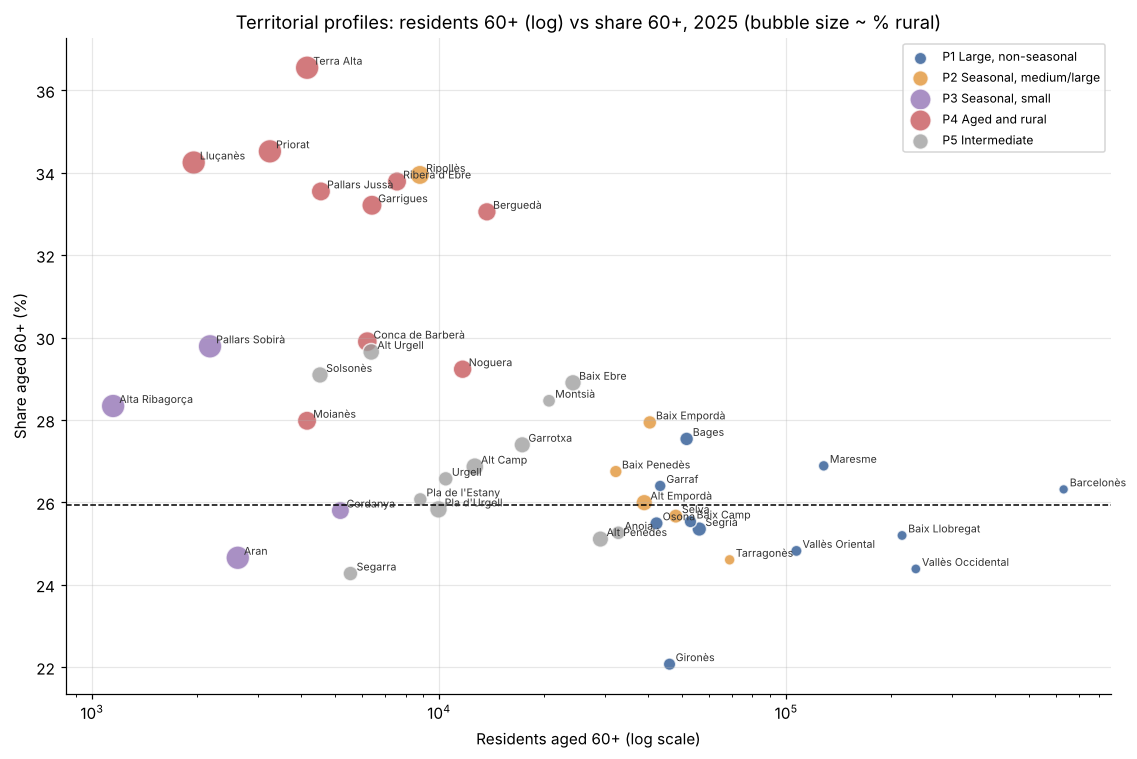

In [13]:
colors = {"P1": "#1F4E8C", "P2": "#E08E2B", "P3": "#8C6BB1", "P4": "#C44E52", "P5": "#9A9A9A"}
fig, ax = plt.subplots(figsize=(10.5, 7))
for p, g in context.groupby("profile"):
    ax.scatter(g["pop_60_plus"], g["share_60_plus"], s=40 + g["pct_rural_cells"] * 2, color=colors[p],
               alpha=0.75, edgecolor="white", label=PROFILE_NAMES[p])
for name, r in context.iterrows():
    ax.annotate(name, (r["pop_60_plus"], r["share_60_plus"]), fontsize=7, xytext=(4, 2), textcoords="offset points",
                color="#333333")
ax.set_xscale("log")
ax.axhline(CATALONIA_SHARE_60, color="black", ls="--", lw=1)
ax.set(title="Territorial profiles: residents 60+ (log) vs share 60+, 2025 (bubble size ~ % rural)",
       xlabel="Residents aged 60+ (log scale)", ylabel="Share aged 60+ (%)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "04_profiles.png", bbox_inches="tight"); plt.show()

### 6.5 Fieldwork candidates

Each profile's members are shown side by side. The suggested candidates and their reasons are given below the tables. They are proposals for discussion with the tutor.

In [14]:
compare_cols = ["pop_60_plus", "share_60_plus", "pct_change_60_plus_2021_2025", "pct_change_60_plus_2025_2040_medium",
                "density_per_km2", "pct_rural_cells", "etca_pct_of_resident_2024", "pct_75plus_living_alone_2021",
                "ist_index_2024", "rfdb_per_capita_eur_2023"]
for p in ["P1", "P2", "P4", "P3", "P5"]:
    print(PROFILE_NAMES[p])
    display(context.loc[context["profile"] == p, compare_cols].sort_values("pop_60_plus", ascending=False).round(1))

P1 Large, non-seasonal


,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,density_per_km2,pct_rural_cells,etca_pct_of_resident_2024,pct_75plus_living_alone_2021,ist_index_2024,rfdb_per_capita_eur_2023
comarca,,,,,,,,,,
Barcelonès,631118,26.3,4.4,18.9,16454.8,0.0,101.8,31.1,100.9,23632.0
Vallès Occidental,236586,24.4,10.7,43.7,1663.8,1.7,96.9,25.8,103.1,21314.0
Baix Llobregat,215903,25.2,9.7,41.9,1763.1,2.4,95.6,25.0,104.2,21188.0
Maresme,128349,26.9,11.2,44.6,1197.8,5.0,99.9,26.3,102.9,20916.0
Vallès Oriental,107069,24.8,11.8,49.5,586.9,7.0,95.0,24.6,101.9,20515.0
Segrià,56189,25.4,9.5,41.4,158.7,25.5,99.2,28.3,89.4,18371.0
Baix Camp,52992,25.5,12.9,50.0,297.7,13.8,109.2,29.3,95.2,17917.0
Bages,51670,27.5,8.2,36.5,171.8,20.5,96.6,27.2,96.8,19637.0
Gironès,46124,22.1,11.8,47.1,363.0,13.0,104.8,28.0,93.4,19308.0


P2 Seasonal, medium/large


,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,density_per_km2,pct_rural_cells,etca_pct_of_resident_2024,pct_75plus_living_alone_2021,ist_index_2024,rfdb_per_capita_eur_2023
comarca,,,,,,,,,,
Tarragonès,68732,24.6,12.9,49.8,874.6,4.7,123.4,29.0,95.8,17903.0
Selva,48075,25.7,13.2,46.8,188.2,23.7,117.3,26.1,89.6,16846.0
Baix Empordà,40463,27.9,12.5,44.6,206.4,20.7,133.6,26.7,90.5,17567.0
Alt Empordà,39001,26.0,9.8,41.0,110.5,39.0,122.8,28.0,83.2,16222.0
Baix Penedès,32291,26.7,15.7,62.1,407.2,14.1,116.9,27.0,90.9,16680.0
Ripollès,8797,33.9,4.5,19.7,27.1,59.8,111.5,29.7,98.0,19977.0


P4 Aged and rural


,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,density_per_km2,pct_rural_cells,etca_pct_of_resident_2024,pct_75plus_living_alone_2021,ist_index_2024,rfdb_per_capita_eur_2023
comarca,,,,,,,,,,
Berguedà,13724,33.1,6.9,24.5,35.0,54.3,100.3,27.0,97.5,19494.0
Noguera,11680,29.2,7.4,28.5,22.4,55.4,96.2,26.9,86.6,16203.0
Ribera d'Ebre,7555,33.8,6.2,17.2,27.0,60.7,99.4,27.4,90.2,17083.0
Garrigues,6399,33.2,4.8,16.8,24.2,68.1,95.7,26.5,90.9,17249.0
Conca de Barberà,6204,29.9,6.7,30.8,31.9,65.5,107.0,28.6,98.2,19133.0
Pallars Jussà,4560,33.5,6.4,20.9,10.1,59.7,108.4,33.4,92.5,17325.0
Terra Alta,4161,36.5,0.5,9.6,15.3,100.0,102.0,18.4,89.4,16072.0
Moianès,4159,28.0,14.0,58.8,44.0,59.9,94.2,23.9,103.3,19801.0
Priorat,3250,34.5,6.3,24.9,18.9,100.0,108.9,28.1,96.2,16611.0


P3 Seasonal, small


,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,density_per_km2,pct_rural_cells,etca_pct_of_resident_2024,pct_75plus_living_alone_2021,ist_index_2024,rfdb_per_capita_eur_2023
comarca,,,,,,,,,,
Cerdanya,5189,25.8,11.8,58.5,36.8,51.7,123.3,28.8,99.9,17261.0
Aran,2626,24.7,14.7,53.4,16.8,100.0,138.7,25.5,103.3,19031.0
Pallars Sobirà,2184,29.8,9.6,39.4,5.3,100.0,143.3,30.0,106.9,17876.0
Alta Ribagorça,1148,28.3,7.0,42.4,9.5,100.0,132.8,31.6,100.7,17128.0


P5 Intermediate


,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,density_per_km2,pct_rural_cells,etca_pct_of_resident_2024,pct_75plus_living_alone_2021,ist_index_2024,rfdb_per_capita_eur_2023
comarca,,,,,,,,,,
Anoia,32829,25.3,10.7,49.2,150.0,22.0,93.4,26.5,98.4,18262.0
Alt Penedès,29151,25.1,11.8,49.1,195.9,38.2,94.9,26.9,100.4,19606.0
Baix Ebre,24300,28.9,7.8,36.5,83.9,39.7,107.3,24.6,86.3,16459.0
Montsià,20730,28.5,8.9,39.6,99.0,16.9,100.8,23.5,84.3,15287.0
Garrotxa,17353,27.4,9.1,33.7,86.2,38.5,98.1,28.5,89.7,19601.0
Alt Camp,12664,26.9,9.5,41.6,87.6,49.2,99.6,28.3,95.1,18908.0
Urgell,10441,26.6,9.4,40.2,67.8,26.6,95.4,27.4,91.3,17174.0
Pla d'Urgell,9952,25.8,7.3,38.5,126.3,47.0,95.3,23.5,88.3,17443.0
Pla de l'Estany,8820,26.1,10.3,42.1,128.7,20.7,97.5,24.4,100.0,20436.0


In [15]:
CANDIDATES = {
    "Vallès Occidental": "P1 — second-largest senior population (237,000), below-average share, fast growth; "
                         "a metropolitan comarca without Barcelona city's exceptional scale",
    "Barcelonès": "P1 alternative — largest market (631,000 seniors, 30 % of Catalonia), but atypical: one city "
                  "dominates and senior growth is the slowest among large comarques",
    "Baix Empordà": "P2 — continuity with the Costa Brava case; highest seasonal load among coastal comarques "
                    "(134 %), above-average share, above-average growth",
    "Selva": "P2 alternative — Costa Brava south, larger senior population (48,000), share near average",
    "Berguedà": "P4 — largest senior population among aged-rural comarques (13,700), share 33 %, income near "
                "the Catalan average; practical access to be judged by the author",
    "Terra Alta": "P4 extreme case — highest senior share in Catalonia (36.5 %) and near-zero senior growth",
}
shortlist = context.loc[list(CANDIDATES), ["profile"] + compare_cols].copy()
shortlist["reason"] = pd.Series(CANDIDATES)
display(shortlist.round(1))

,profile,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,density_per_km2,pct_rural_cells,etca_pct_of_resident_2024,pct_75plus_living_alone_2021,ist_index_2024,rfdb_per_capita_eur_2023,reason
comarca,,,,,,,,,,,,
Vallès Occidental,P1,236586,24.4,10.7,43.7,1663.8,1.7,96.9,25.8,103.1,21314.0,"P1 — second-largest senior population (237,000..."
Barcelonès,P1,631118,26.3,4.4,18.9,16454.8,0.0,101.8,31.1,100.9,23632.0,"P1 alternative — largest market (631,000 senio..."
Baix Empordà,P2,40463,27.9,12.5,44.6,206.4,20.7,133.6,26.7,90.5,17567.0,P2 — continuity with the Costa Brava case; hig...
Selva,P2,48075,25.7,13.2,46.8,188.2,23.7,117.3,26.1,89.6,16846.0,"P2 alternative — Costa Brava south, larger sen..."
Berguedà,P4,13724,33.1,6.9,24.5,35.0,54.3,100.3,27.0,97.5,19494.0,P4 — largest senior population among aged-rura...
Terra Alta,P4,4161,36.5,0.5,9.6,15.3,100.0,102.0,18.4,89.4,16072.0,P4 extreme case — highest senior share in Cata...


### 6.6 Municipal structure of the candidate comarques (2025)

For supply mapping and survey sampling, what matters is where seniors actually live within each comarca: in one main town, or spread over many small municipalities.

In [16]:
census_mun_2025 = pd.concat([read_jsonstat(f) for f in sorted(IDESCAT_API_RAW.glob("censph_539_5976_mun_2025_total_*.json"))],
                            ignore_index=True)
census_mun_2025 = census_mun_2025.loc[census_mun_2025["MUN"] != "TOTAL"].copy()
census_mun_2025["age_lower"] = census_mun_2025["AGE"].map(age_group_lower_bound)
mun = pd.DataFrame({
    "pop_total": census_mun_2025.loc[census_mun_2025["AGE"] == "TOTAL"].set_index("MUN")["value"],
    "pop_60_plus": census_mun_2025.loc[census_mun_2025["age_lower"] >= 60].groupby("MUN")["value"].sum(),
})
mun["share_60_plus"] = 100 * mun["pop_60_plus"] / mun["pop_total"]
mun = mun.join(degurba_mun.set_index("mun_code")[["mun_name", "comarca_name", "PERC_RUR_AREA"]])
assert mun["comarca_name"].notna().all() and len(mun) == 947
assert (mun.groupby("comarca_name")["pop_60_plus"].sum().reindex(context.index) == context["pop_60_plus"]).all()

def municipal_structure(df):
    s = df.sort_values("pop_60_plus", ascending=False)
    total = s["pop_60_plus"].sum()
    return pd.Series({
        "municipalities": len(s),
        "residents_60_plus": total,
        "largest_municipality": s["mun_name"].iloc[0],
        "pct_of_60_plus_in_largest": 100 * s["pop_60_plus"].iloc[0] / total,
        "municipalities_for_75pct_of_60_plus": int((s["pop_60_plus"].cumsum() / total < 0.75).sum() + 1),
        "municipalities_under_200_seniors": int((s["pop_60_plus"] < 200).sum()),
        "pct_of_60_plus_in_rural_municipalities": 100 * s.loc[s["PERC_RUR_AREA"] >= 50, "pop_60_plus"].sum() / total,
    })

structure = mun.groupby("comarca_name").apply(municipal_structure)
display(structure.loc[list(CANDIDATES)].round(1))

,municipalities,residents_60_plus,largest_municipality,pct_of_60_plus_in_largest,municipalities_for_75pct_of_60_plus,municipalities_under_200_seniors,pct_of_60_plus_in_rural_municipalities
comarca_name,,,,,,,
Vallès Occidental,23,236586.0,Sabadell,24.3,6,1,0.6
Barcelonès,5,631118.0,Barcelona,73.0,2,0,0.0
Baix Empordà,36,40463.0,Sant Feliu de Guíxols,16.0,7,17,14.4
Selva,26,48075.0,Blanes,24.2,9,3,17.3
Berguedà,31,13724.0,Berga,39.1,6,21,55.8
Terra Alta,12,4161.0,Gandesa,22.0,6,4,100.0


In [17]:
for comarca in CANDIDATES:
    t = mun.loc[mun["comarca_name"] == comarca].sort_values("pop_60_plus", ascending=False)
    print(f"\n{comarca}: top municipalities by residents aged 60+")
    display(t[["mun_name", "pop_total", "pop_60_plus", "share_60_plus", "PERC_RUR_AREA"]].head(8).round(1)
            .rename(columns={"PERC_RUR_AREA": "pct_rural_cells"}).reset_index(drop=True))


Vallès Occidental: top municipalities by residents aged 60+


,mun_name,pop_total,pop_60_plus,share_60_plus,pct_rural_cells
0,Sabadell,224589.0,57424.0,25.6,0.1
1,Terrassa,232676.0,55958.0,24.0,0.3
2,Sant Cugat del Vallès,97959.0,21530.0,22.0,0.9
3,Rubí,82825.0,19191.0,23.2,0.8
4,Cerdanyola del Vallès,58264.0,16643.0,28.6,0.4
5,Ripollet,39773.0,8911.0,22.4,0.0
6,Barberà del Vallès,34031.0,8692.0,25.5,0.0
7,Montcada i Reixac,37446.0,8651.0,23.1,2.2



Barcelonès: top municipalities by residents aged 60+


,mun_name,pop_total,pop_60_plus,share_60_plus,pct_rural_cells
0,Barcelona,1713247.0,460936.0,26.9,0.0
1,"Hospitalet de Llobregat, l'",292161.0,70588.0,24.2,0.1
2,Badalona,230642.0,59881.0,26.0,0.1
3,Santa Coloma de Gramenet,123250.0,30590.0,24.8,0.0
4,Sant Adrià de Besòs,38980.0,9123.0,23.4,0.0



Baix Empordà: top municipalities by residents aged 60+


,mun_name,pop_total,pop_60_plus,share_60_plus,pct_rural_cells
0,Sant Feliu de Guíxols,23060.0,6455.0,28.0,1.5
1,Palafrugell,24556.0,6314.0,25.7,7.2
2,Palamós i Sant Joan,18921.0,5498.0,29.1,1.4
3,Calonge i Sant Antoni,12268.0,3650.0,29.8,16.4
4,"Castell d'Aro, Platja d'Aro i s'Agaró",12889.0,3484.0,27.0,4.3
5,Torroella de Montgrí,12507.0,3366.0,26.9,37.8
6,"Bisbal d'Empordà, la",11731.0,2896.0,24.7,0.8
7,Santa Cristina d'Aro,5972.0,1564.0,26.2,32.4


... (2 outputs left out)


Berguedà: top municipalities by residents aged 60+


,mun_name,pop_total,pop_60_plus,share_60_plus,pct_rural_cells
0,Berga,17539.0,5367.0,30.6,3.4
1,Gironella,5082.0,1691.0,33.3,100.0
2,Puig-reig,4558.0,1544.0,33.9,95.2
3,Bagà,2167.0,815.0,37.6,100.0
4,Avià,2263.0,696.0,30.8,19.1
5,Casserres,1665.0,576.0,34.6,100.0
6,"Pobla de Lillet, la",1106.0,491.0,44.4,100.0
7,Cercs,1236.0,449.0,36.3,100.0



Terra Alta: top municipalities by residents aged 60+


,mun_name,pop_total,pop_60_plus,share_60_plus,pct_rural_cells
0,Gandesa,3151.0,917.0,29.1,100.0
1,Batea,1873.0,678.0,36.2,100.0
2,Horta de Sant Joan,1156.0,427.0,36.9,100.0
3,"Fatarella, la",841.0,412.0,49.0,100.0
4,Corbera d'Ebre,1024.0,377.0,36.8,100.0
5,"Pinell de Brai, el",948.0,347.0,36.6,100.0
6,Vilalba dels Arcs,613.0,249.0,40.6,100.0
7,Bot,545.0,237.0,43.5,100.0


### 6.7 Export

In [18]:
export = context.drop(columns=["size_third"]).assign(size_third=context["size_third"].astype(str))
export.reset_index().to_csv(DATA_PROCESSED / "comarca_profiles_context_2025.csv", index=False, encoding="utf-8-sig")
shortlist.reset_index().rename(columns={"index": "comarca"}).to_csv(
    DATA_PROCESSED / "fieldwork_candidates.csv", index=False, encoding="utf-8-sig")
mun.reset_index().rename(columns={"MUN": "mun_code", "PERC_RUR_AREA": "pct_rural_cells"}).to_csv(
    DATA_PROCESSED / "municipality_seniors_2025.csv", index=False, encoding="utf-8-sig")
ict_age.reset_index().rename(columns={"category": "age_group"}).to_csv(
    DATA_PROCESSED / "ict_use_by_age_catalonia_2025.csv", index=False, encoding="utf-8-sig")
print("Exported:", [p.name for p in sorted(DATA_PROCESSED.glob("*")) if p.stem in
      {"comarca_profiles_context_2025", "fieldwork_candidates", "municipality_seniors_2025", "ict_use_by_age_catalonia_2025"}])

Exported: ['comarca_profiles_context_2025.csv', 'fieldwork_candidates.csv', 'ict_use_by_age_catalonia_2025.csv', 'municipality_seniors_2025.csv']


## 7. Interpretation

The points below separate **facts** (measured above), **observations** (patterns in them) and **hypotheses** (to test later).

**Living alone (facts, 2021).** 28.1 % of people aged 75+ in Catalonia live alone, about 205,000 people. By comarca the share ranges from 18.4 % (Terra Alta) to 33.4 % (Pallars Jussà). Barcelonès is third-highest (31.1 %, about 78,000 people). The three largest comarques hold 56 % of all people aged 75+ living alone.

*Observation:* living alone is **not** a rural phenomenon. Its share is essentially unrelated to senior size, share or rural settlement (rank correlations −0.08 to 0.18). In absolute numbers it is concentrated where the population is, above all in Barcelona.

**Settlement and socioeconomic level (facts).** Senior population size is almost a mirror of density and urbanisation: rank correlation 0.91 with density and −0.90 with the share living in rural cells. The senior *share* rises with rurality (0.66). The socioeconomic index (IST 2024) ranges from 83 (Alt Empordà) to 107 (Pallars Sobirà) and is unrelated to senior size or share (|ρ| ≤ 0.10). Notably, the seasonal coastal comarques sit below the Catalan average (P2 median IST 90.7).

**Digital use (facts, Catalonia, ages 16–74, 2025).** Among people aged 65–74, 92.7 % used the internet in the last 3 months and 90.2 % use it at least weekly. These are close to younger groups. But only **36.1 %** bought something online, about half the rate of people aged 25–54 (69–76 %). Nothing is known from these sources about people aged 75+.

*Observation:* for 65–74 the gap is not in *being online* but in *transacting online*.

**Profiles (rule-based).**

| Profile | Comarques | % of Catalonia's 60+ | Typical traits (medians) |
|---|---|---|---|
| P1 Large, non-seasonal | 11 | 76.5 % | Average share (25.5 %), urban, IST about 101 |
| P2 Seasonal, medium/large | 6 | 11.3 % | Fastest recent senior growth (12.7 %), coastal tourist load, IST about 91 |
| P3 Seasonal, small | 4 | 0.5 % | Pyrenean, very low density, high seasonal load |
| P4 Aged and rural | 10 | 3.0 % | Share 33 %, slowest growth (6.5 %), mostly rural |
| P5 Intermediate | 12 | 8.7 % | Close to average on most variables |

The grouping is fairly stable. Moving the seasonal threshold to 105 % moves 6 comarques, the rural threshold changes 2–4, and the share threshold none. Ripollès (seasonal load 111.5 %) is the clearest borderline case: it sits in P2 but is demographically closer to P4.

**Fieldwork candidates (proposals).** The six candidates span the main profiles and also differ in municipal structure:

- **Barcelonès:** 73 % of its seniors live in one city.
- **Vallès Occidental:** 6 municipalities hold 75 % of its seniors, all urban.
- **Baix Empordà:** seniors spread over 36 municipalities, 17 of them with fewer than 200 seniors.
- **Berguedà:** 56 % of its seniors live in rural municipalities.
- **Terra Alta:** entirely rural, with 12 small municipalities.

This variety matters for both supply mapping (how many organisers to contact) and survey logistics.

**Hypotheses arising.**
- H4: Among seniors aged 65–74, a marketplace limited to *discovery and information* could reach most people. One requiring *online booking or payment* could exclude a large share (only 36 % buy online). The survey should measure willingness to book and pay online, separately for 65–74 and 75+.
- H5: Seniors aged 75+ who live alone (about 205,000) are a group for whom social activities may matter most. They are concentrated in Barcelona, which makes reaching them through a digital channel an open question.
- H6: Rural, aged comarques (P4) may rely more on informal and municipal channels (casals, town halls) than on digital ones. Supply there may be less visible online. This is a reason to check offline sources in the inventory.

## 8. Limitations

- **Mixed years.** Living alone is from 2021, IST and education from 2024, urbanisation and population from 2025, and seasonal load from 2024. Each variable carries its year.
- **Living alone uses 2021 boundaries.** For Osona, Segarra and Solsonès the boundaries differ from 2025, and Lluçanès has no value. The estimated counts multiply a rounded percentage by a population, so they are approximate.
- **Context is not age-specific.** IST, education and urbanisation describe all residents, not seniors. A comarca's average says little about its seniors' education or income.
- **Digital use is only known for Catalonia as a whole and for ages up to 74.** No official source in this project gives digital use for people 75+, or by comarca. The survey will have to cover this.
- **Profiles are rule-based simplifications.** The thresholds (thirds of size, 110 % seasonal load, 50 % rural, Catalan share) are conventions. The sensitivity check shows which comarques sit on a boundary. Profiles are a sampling aid, not a segmentation of the market.
- **Candidates are suggestions.** Practical constraints (travel, contacts, time, language) are not in the data and must be weighed by the author and tutor.
- **Correlations across 43 comarques are descriptive.** They are not evidence of causal relationships.

## 9. Conclusions and next steps

**Conclusions**

1. The context variables do not overturn notebook 03. Size, density and urbanisation go together; senior share goes with rurality; living alone and the socioeconomic index cut across both.
2. Five transparent profiles describe the comarques. P1 (11 large, non-seasonal comarques) holds three quarters of all seniors; P4 (10 aged, rural comarques) holds 3 %. The profiles are stable under reasonable changes of their thresholds.
3. Among people aged 65–74 almost everyone is online, but only about a third buy online. For 75+ there is no data. Digital *transactions*, not access, look like the critical uncertainty for a marketplace.
4. Six candidate comarques are proposed for fieldwork, covering the main profiles and very different municipal structures: Vallès Occidental or Barcelonès (P1), Baix Empordà or Selva (P2), Berguedà or Terra Alta (P4).

**Next steps (recommended)**

- [ ] Agree the fieldwork comarques with the tutor: one per profile P1, P2 and P4, optionally P3.
- [ ] Design the **activity-supply inventory**: data schema, sources per municipality (municipal agendas, casals de gent gran, associations registers, cultural agendas in open data), and a pilot in one candidate comarca.
- [ ] Design the **survey**. Measure, separately for 60–74 and 75+: activity participation, discovery channels, barriers, digital use, and willingness to book and pay online. Plan recruitment, sample size, ethics and data protection.
- [ ] Look for age-specific sources on cultural and social participation (e.g. Idescat or INE surveys) to set the survey questions against official benchmarks.